1(b) Split data to train and test

In [5]:
from pathlib import Path
import pandas as pd

data_path = Path("../data/AReM")

columns = [
    "time", "avg_rss12", "var_rss12",
    "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"
]

train_data, test_data = [], []
train_labels, test_labels = [], []

for folder in sorted(data_path.iterdir()):
    if not folder.is_dir():
        continue

    activity = folder.name

    for file in sorted(folder.glob("dataset*.csv")):
        number = int(file.stem.replace("dataset", ""))

        data = pd.read_csv(
            file,
            comment="#",
            header=None,
            sep=r"[,\s]+",
            engine="python",
            usecols=range(7),
            names=columns
        )

        # First 2 files for bending; first 3 files for other activities
        test_limit = 2 if activity in ["bending1", "bending2"] else 3

        if number <= test_limit:
            test_data.append(data)
            test_labels.append(activity)
        else:
            train_data.append(data)
            train_labels.append(activity)

print("Training samples:", len(train_data))
print("Test samples:", len(test_data))

Training samples: 69
Test samples: 19


1(c)i time-domain features are usually used:

Minimum and maximum: the lowest and highest values.

Mean and median: measures of the central value.

Standard deviation and variance: measures of how spread out the values are.

First and third quartiles: the 25th and 75th percentiles.

Range and interquartile range: maximum minus minimum, and third quartile minus first quartile.

Skewness and kurtosis: measures of the shape of the value distribution.

Root mean square (RMS) and energy: measures of signal magnitude.

Autocorrelation: the relationship between a time series and its lagged values.

Mean absolute change: the average absolute difference between consecutive values.

Number of peaks and zero crossings: measures of fluctuations in the signal.

1(c)ii

In [6]:
all_data = train_data + test_data

rows = []

for data in all_data:
    features = {}

    for i, column in enumerate(data.columns[1:], start=1):
        series = data[column]

        features[f"min{i}"] = series.min()
        features[f"max{i}"] = series.max()
        features[f"mean{i}"] = series.mean()
        features[f"median{i}"] = series.median()
        features[f"std{i}"] = series.std()
        features[f"1st_quart{i}"] = series.quantile(0.25)
        features[f"3rd_quart{i}"] = series.quantile(0.75)

    rows.append(features)

features_df = pd.DataFrame(rows)
features_df.index = range(1, len(features_df) + 1)
features_df.index.name = "Instance"

display(features_df)
print(features_df.shape)

,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,...,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
Instance,,,,,,,,,,,,,,,,,,,,,
1,35.00,47.40,43.954500,44.330,1.558835,43.00,45.0000,0.0,1.70,0.426250,...,1.999604,35.3625,36.500,0.0,1.79,0.493292,0.430,0.513506,0.000,0.940
2,33.00,47.75,42.179812,43.500,3.670666,39.15,45.0000,0.0,3.00,0.696042,...,3.849448,30.4575,36.330,0.0,2.18,0.613521,0.500,0.524317,0.000,1.000
3,33.00,45.75,41.678063,41.750,2.243490,41.33,42.7500,0.0,2.83,0.535979,...,2.411026,28.4575,31.250,0.0,1.79,0.383292,0.430,0.389164,0.000,0.500
4,37.00,48.00,43.454958,43.250,1.386098,42.50,45.0000,0.0,1.58,0.378083,...,2.488862,22.2500,24.000,0.0,5.26,0.679646,0.500,0.622534,0.430,0.870
5,36.25,48.00,43.969125,44.500,1.618364,43.31,44.6700,0.0,1.50,0.413125,...,3.318301,20.5000,23.750,0.0,2.96,0.555312,0.490,0.487826,0.000,0.830
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,35.50,46.25,43.174938,43.670,1.989052,42.50,44.5000,0.0,2.12,0.506583,...,2.983976,12.7500,16.500,0.0,5.72,0.911979,0.830,0.666161,0.470,1.220
85,32.75,47.00,42.760562,44.500,3.398919,41.33,45.3725,0.0,3.34,0.486167,...,4.296574,13.0000,18.565,0.0,5.73,0.842271,0.710,0.722165,0.430,1.090
86,19.33,43.50,34.227771,35.500,4.889576,30.50,37.7500,0.0,14.50,3.995729,...,3.092094,14.7500,18.670,0.0,9.74,3.394125,3.100,1.792090,2.105,4.425


(88, 42)


1(c)iii Standard Deviation and bootsrap confidence interval

In [7]:
import numpy as np

rng = np.random.default_rng(42)

# Standard deviation of each feature
feature_std = features_df.std()

# Bootstrap: sample 88 instances with replacement each time
bootstrap_std = []

for _ in range(10000):
    indices = rng.choice(len(features_df), size=len(features_df), replace=True)
    sample = features_df.iloc[indices]
    bootstrap_std.append(sample.std().to_numpy())

# 90% percentile confidence intervals
lower, upper = np.percentile(bootstrap_std, [5, 95], axis=0)

std_results = pd.DataFrame({
    "Standard Deviation": feature_std,
    "90% CI Lower": lower,
    "90% CI Upper": upper
})

display(std_results)

,Standard Deviation,90% CI Lower,90% CI Upper
min1,9.569975,8.244286,10.758793
max1,4.394362,3.327264,5.306152
mean1,5.335718,4.705556,5.878507
median1,5.440054,4.795744,5.993590
std1,1.772153,1.573015,1.949089
1st_quart1,6.153590,5.569467,6.639432
3rd_quart1,5.138925,4.327216,5.826745
min2,0.000000,0.000000,0.000000
max2,5.062729,4.617742,5.410284
mean2,1.574164,1.394410,1.706190


1(c)iv I select mean, standard deviation, and maximum. The mean represents the overall signal level, the standard deviation measures variability, and the maximum captures peak values. Together, they may help distinguish different activities.

2

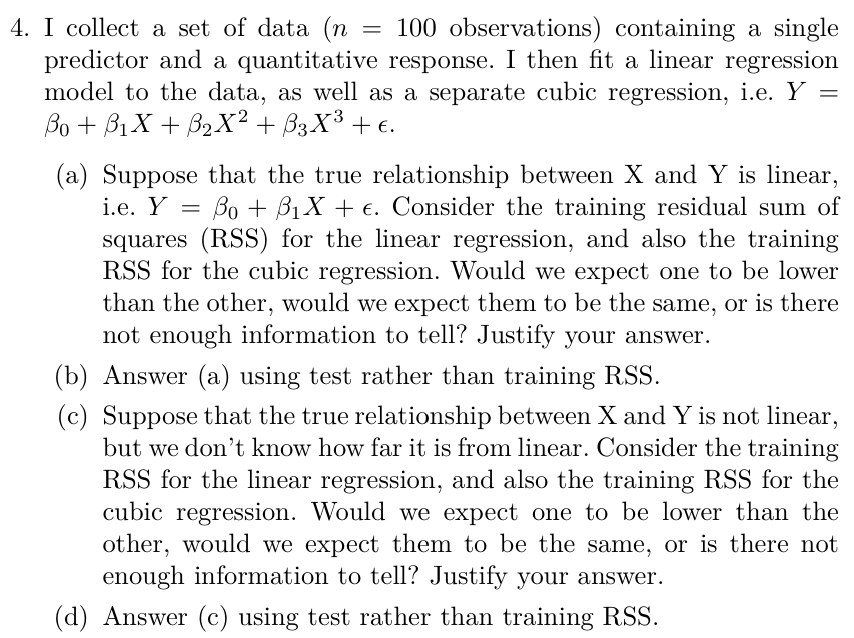

(a) The cubic regression will have training RSS less than or equal to that of the linear regression. The linear model is a special case of the cubic model where β₂ = β₃ = 0, so adding these terms cannot increase the minimum training RSS.

(b) We expect the linear regression to have lower test RSS because the true relationship is linear. The extra terms in the cubic model can fit noise and increase variance. However, this is not guaranteed for a particular test set.

(c) The cubic regression will still have training RSS less than or equal to that of the linear regression. This holds regardless of the true relationship because the cubic model includes the linear model as a special case.

(d) There is not enough information to determine which model will have lower test RSS. If the relationship is close to linear, the linear model may perform better due to lower variance. If the nonlinearity is substantial and well captured by the cubic model, the cubic model may perform better due to lower bias.
